In [1]:
import os
import logging
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # 0 (default) = all messages, 1 = INFO messages, 2 = INFO and WARNING messages, 3 = only ERROR messages
logging.getLogger('tensorflow').setLevel(logging.ERROR)  # Suppress TensorFlow INFO and WARNING messages
import wfdb
import tensorflow as tf
from scipy.signal import butter, filtfilt, iirnotch
from matplotlib import pyplot as plt
import numpy as np

2024-03-04 09:41:17.184555: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-03-04 09:41:17.184633: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-03-04 09:41:17.185807: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
def force_data(path, force_file):
    """
    Loads and preprocesses a force signal from a file.
    
    Arguments:
        - `path`: Path to the directory containing the force data file.
        - `force_file`: Filename of the force data file.
    
    Returns:
        A numpy array containing the filtered force signal.
    
    Raises:
        ValueError: If the finger name is not found in the filename.
        
    Details:
        - This function assumes the force data file follows a naming convention where the finger name is part of the filename.
        - It extracts the force signal for the specified finger from the file.
        - The first 5 samples are discarded, potentially corresponding to non-data values.
        - The signal is then filtered using a 4th order low-pass Butterworth filter with a specified cutoff frequency.
    
    Example usage:
    
    ```python
    force_signal = force_data(path, "finger2_data.txt")
    ```
    """
    finger_names = ["finger1", "finger2", "finger3", "finger4", "finger5"]
    # Sample rate and desired cutoff frequency (in Hz)
    fs = 100.0
    cutoff = 5.0
    for i, name in enumerate(finger_names):
        if name in force_file:
            force_signal = wfdb.rdsamp(os.path.join(path, force_file[:-4]))[0]
            force_signal = force_signal[5:]
            ######################################################
            # Filter the high frequencies
            ######################################################
            force_signal = butter_lowpass_filter(force_signal, cutoff, fs, order=4)
            return force_signal

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

In [3]:
path = 'data/1dof_dataset/'
emg_path = 'subject01_session1/1dof_preprocess_finger1_sample1.hea'
force_path = 'subject01_session1/1dof_force_finger1_sample1.hea'

In [4]:
emg_signal = wfdb.rdsamp(os.path.join(path, emg_path[:-4]))[0]
emg_signal = tf.cast(emg_signal, dtype=tf.float32)
force_signal = force_data(path, force_path)

In [5]:
print(f"Shape of emg signal: {emg_signal.shape}")
print(f"Shape of force signal: {force_signal.shape}")

Shape of emg signal: (51200, 256)
Shape of force signal: (2495, 5)


In [6]:
import numpy as np
from scipy import interpolate

def interpolate_force_to_emg(force_signal, emg_signal):
    """
    Interpola um sinal de força para ter o mesmo formato que um sinal de EMG.

    Parâmetros:
        - force_signal: array numpy com o sinal de força de entrada, com shape (n_samples_force, n_channels)
        - emg_signal: array numpy com o sinal de EMG de referência, com shape (n_samples_emg, n_channels)
    
    Retorna:
        - interpolated_signals: array numpy com os sinais de força interpolados, com shape (n_samples_emg, n_channels)
    
    Exemplo de uso:
        - interpolated_force = interpolate_force_to_emg(force_signal, emg_signal)
    """
    interpolated_signals = np.zeros((emg_signal.shape[0], force_signal.shape[1]))  # Array para armazenar os sinais interpolados

    for i in range(force_signal.shape[1]):  # Para cada canal de força
        x = np.arange(0, force_signal.shape[0])  # Índices originais do sinal de força
        y = force_signal[:, i]  # Valor do sinal de força
        f = interpolate.interp1d(x, y, kind='cubic')  # Função de interpolação cúbica
        x_new = np.linspace(0, force_signal.shape[0] - 1, emg_signal.shape[0])  # Novos índices para o sinal interpolado
        interpolated_signals[:, i] = f(x_new)  # Interpolar o sinal de força para o comprimento do sinal de EMG

    return interpolated_signals

In [7]:
interpolated_force = interpolate_force_to_emg(force_signal, emg_signal)

print(f"Shape of force signal: {interpolated_force.shape}")

Shape of force signal: (51200, 5)


In [8]:
def plot_signals(original_signal, interpolated_signal, signal_names):
    num_channels = original_signal.shape[1]
    fig, axs = plt.subplots(num_channels, 2, figsize=(14, 8))

    for i in range(num_channels):
        axs[i, 0].plot(original_signal[:, i], label='Original')
        axs[i, 0].set_title(f'Channel {i+1} - Original')
        axs[i, 1].plot(interpolated_signal[:, i], label='Interpolated', color='orange')
        axs[i, 1].set_title(f'Channel {i+1} - Interpolated')
        axs[i, 0].legend()
        axs[i, 1].legend()

    plt.tight_layout()
    plt.show()

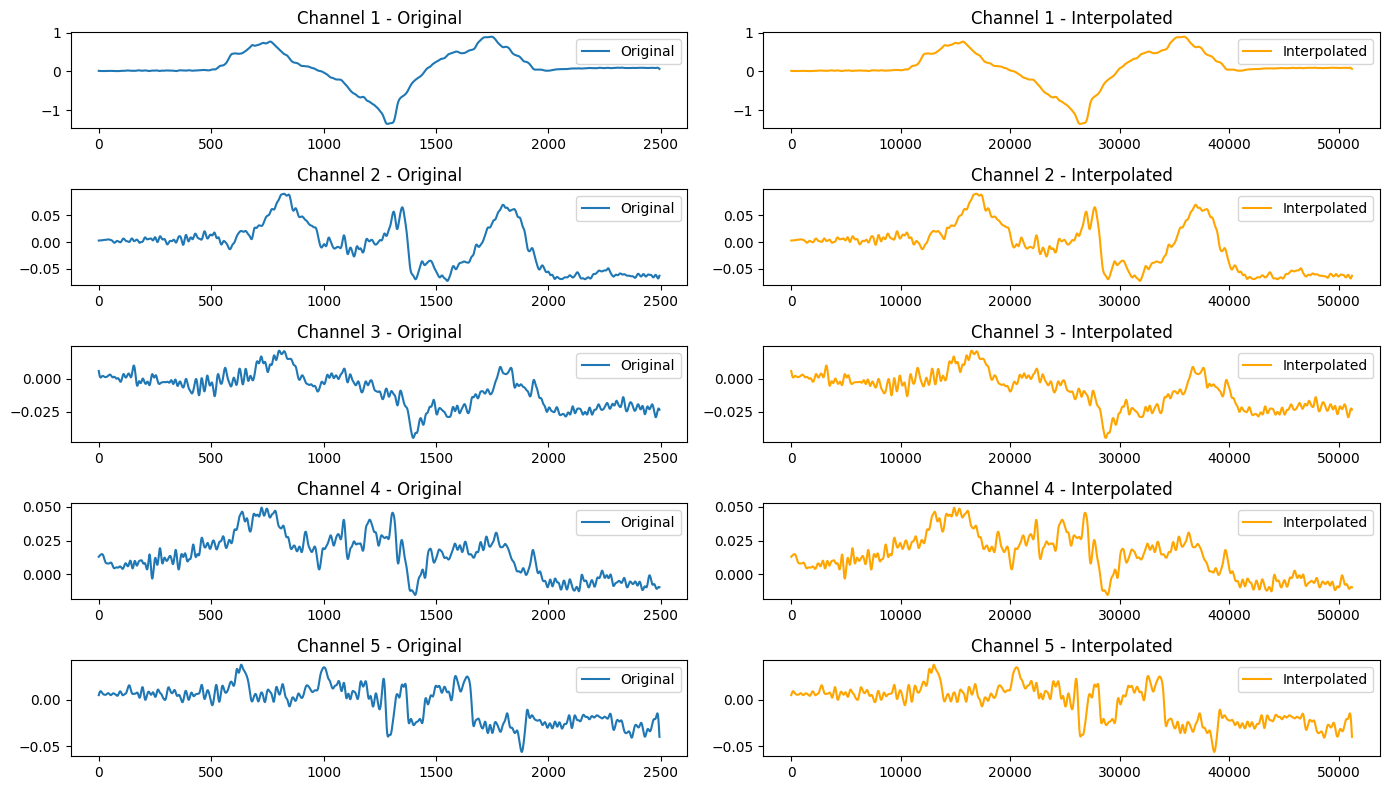

In [9]:
plot_signals(force_signal/0.3, interpolated_force/0.3, signal_names=["Force Channel 1", "Force Channel 2", "Force Channel 3", "Force Channel 4", "Force Channel 5"])

In [10]:
def force_data(path, force_file):
    """
    Loads and preprocesses a force signal from a file.
    
    Arguments:
        - `path`: Path to the directory containing the force data file.
        - `force_file`: Filename of the force data file.
    
    Returns:
        A numpy array containing the filtered force signal.
    
    Raises:
        ValueError: If the finger name is not found in the filename.
        
    Details:
        - This function assumes the force data file follows a naming convention where the finger name is part of the filename.
        - It extracts the force signal for the specified finger from the file.
        - The first 5 samples are discarded, potentially corresponding to non-data values.
        - The signal is then filtered using a 4th order low-pass Butterworth filter with a specified cutoff frequency.
    
    Example usage:
    
    ```python
    force_signal = force_data(path, "finger2_data.txt")
    ```
    """
    finger_names = ["finger1", "finger2", "finger3", "finger4", "finger5"]
    # Sample rate and desired cutoff frequency (in Hz)
    fs = 100.0
    cutoff = 5.0
    for i, name in enumerate(finger_names):
        if name in force_file:
            force_signal = wfdb.rdsamp(os.path.join(path, force_file[:-4]))[0]
            force_signal = force_signal[5:]
            # Filter the high frequencies
            force_signal = butter_lowpass_filter(force_signal, cutoff, fs, order=4)
            return force_signal

def interpolate_force_to_emg(force_signal, emg_signal):
    """
    Interpolates a force signal to have the same shape as an EMG signal.

    Parameters:
        - force_signal: numpy array with the input force signal, with shape (n_samples_force, n_channels)
        - emg_signal: numpy array with the reference EMG signal, with shape (n_samples_emg, n_channels)
    
    Returns:
        - interpolated_signals: numpy array with the interpolated force signals, with shape (n_samples_emg, n_channels)
    
    Example usage:
        - interpolated_force = interpolate_force_to_emg(force_signal, emg_signal)
    """
    interpolated_signals = np.zeros((emg_signal.shape[0], force_signal.shape[1]))  # Array to store interpolated signals

    for i in range(force_signal.shape[1]):  # For each force channel
        x = np.arange(0, force_signal.shape[0])  # Original indices of the force signal
        y = force_signal[:, i]  # Value of the force signal
        f = interpolate.interp1d(x, y, kind='cubic')  # Cubic interpolation function
        x_new = np.linspace(0, force_signal.shape[0] - 1, emg_signal.shape[0])  # New indices for the interpolated signal
        interpolated_signals[:, i] = f(x_new)  # Interpolate the force signal to the length of the EMG signal

    return interpolated_signals

def synced_windows(emg_signal, force_signal, window_size=100, shift=1):
    """
    Create windows from EMG and force signals using tf.slice.

    Arguments:
        emg_signal: EMG signal tensor.
        force_signal: Force signal tensor.
        emg_window_size: Size of the EMG window (default: 100).
        force_window_size: Size of the force window (default: 1).
    
    Returns:
        A TensorFlow dataset containing synchronized EMG and force windows.
    """
    # Adjust the signal
    emg_windows = tf.data.Dataset.from_tensor_slices(emg_signal[:-window_size-shift+1])
    force_windows = tf.data.Dataset.from_tensor_slices(force_signal[window_size+shift-1:-1])
    
    # Extract EMG windows
    emg_windows = emg_windows.window(window_size, shift=shift, drop_remainder=True)
    force_windows = force_windows.window(1, shift=shift)

    # Convert to windows of desired size
    emg_windows = emg_windows.flat_map(lambda x: x.batch(window_size))
    force_windows = force_windows.flat_map(lambda x: x.batch(1))

    # Create the dataset
    dataset = tf.data.Dataset.zip((emg_windows, force_windows))
    return dataset

def create_synced_datasets(path, emg_files, force_files, window_size=100, stride=1):
    """
    Creates a TensorFlow dataset by loading, processing, and combining synchronized EMG and force signals from multiple files.
    
    Arguments:
        - `path`: Path to the directory containing the data files.
        - `emg_files`: List of filenames for the EMG files.
        - `force_files`: List of filenames for the force files.
        - `window_size`: Size of the window in samples to split the signals (default: 100).
        - `stride`: Step size of the window in samples when splitting the signals (default: 1).
    
    Returns:
        A TensorFlow dataset containing synchronized windows of EMG and force signals from all the files.
    """
    datasets = []

    if not isinstance(emg_files, list):
        emg_files = [emg_files]
    if not isinstance(force_files, list):
        force_files = [force_files]

    path = str(path)[2:-1]
    emg_files = [str(byte_string)[2:-1] for byte_string in emg_files]
    force_files = [str(byte_string)[2:-1] for byte_string in force_files]

    for emg_file, force_file in zip(emg_files, force_files):
        # Load EMG and force signals
        emg_signal = wfdb.rdsamp(os.path.join(path, emg_file[:-4]))[0]
        emg_signal = tf.cast(emg_signal, dtype=tf.float32)

        force_signal = force_data(path, force_file)
        force_signal = interpolate_force_to_emg(force_signal, emg_signal)

        # Create the dataset for the finguers
        finger_dataset = synced_windows(emg_signal, force_signal)
        # Apply preprocessing to force signals
        finger_dataset = finger_dataset.map(lambda x, y: (x, preprocess_force(y)))

        datasets.append(finger_dataset)

    dataset = datasets[0]
    for i in range(1, len(datasets)):
        dataset = dataset.concatenate(datasets[i])
    return dataset

def create_synced_datasets_generator(paths, emg_files_list, force_files_list, window_size=100):
    """
    Yields datasets generated from processing multiple data files in a generator fashion.

    Arguments:
        - `paths`: A list of paths to the directories containing the data files.
        - `emg_files_list`: A list of lists containing filenames for the EMG files for each path.
        - `force_files_list`: A list of lists containing filenames for the force files for each path.
        - `window_size`: Size of the window in samples to split the signals (default: 100).

    Yields:
        A TensorFlow dataset containing synchronized windows of EMG and force signals from a single file pair.
    """
    for path in paths:
        for emg_file, force_file in zip(emg_files_list, force_files_list):
            yield from create_synced_datasets(path, emg_file, force_file, window_size=window_size)

def preprocess_force(force):
    # Reshape label to match the expected shape
    force = tf.squeeze(force, axis=0)
    return force

def generate_dataset(paths, emg_paths, force_paths):
    return create_synced_datasets_generator(paths, emg_paths, force_paths)

In [11]:
window_size=100
stride=1

number_of_emg_windows = int(np.floor((interpolated_force[:-100].shape[0] - window_size) / stride + 1))
number_of_force_windows = int(np.floor((interpolated_force[100:].shape[0] - 1) / stride + 1))

print(f"Number of emg windows of the dataset: {number_of_emg_windows}")
print(f"Number of force windows of the dataset: {number_of_force_windows}")

Number of emg windows of the dataset: 51001
Number of force windows of the dataset: 51100


In [12]:
path = ['data/1dof_dataset/']
emg_path = ['subject01_session1/1dof_preprocess_finger1_sample1.hea']
force_path = ['subject01_session1/1dof_force_finger1_sample1.hea']

# Use `tf.data.Dataset.from_generator` to create a dataset from the generator
dataset = tf.data.Dataset.from_generator(
    generate_dataset,
    args=(path, emg_path, force_path),
    output_types=(tf.float32, tf.float32),  # Define output types (EMG, force)
    output_shapes=(tf.TensorShape([100, 256]),
                  tf.TensorShape([5,]))
)

In [13]:
dataset.batch(4)

for emg_window, force_target in dataset.take(2):
    print("EMG Window:")
    print(emg_window.shape)
    print("Force Target:")
    print(force_target.shape)
    print()

EMG Window:
(100, 256)
Force Target:
(5,)

EMG Window:
(100, 256)
Force Target:
(5,)



In [14]:
dataset

<_FlatMapDataset element_spec=(TensorSpec(shape=(100, 256), dtype=tf.float32, name=None), TensorSpec(shape=(5,), dtype=tf.float32, name=None))>

In [15]:
force_signal = []
for emg, f in dataset:
    force_signal.append(f)
# Converter a lista de previsões em um tensor
force_signal = tf.concat(force_signal, axis=0)

In [16]:
print(len(force_signal))

255005


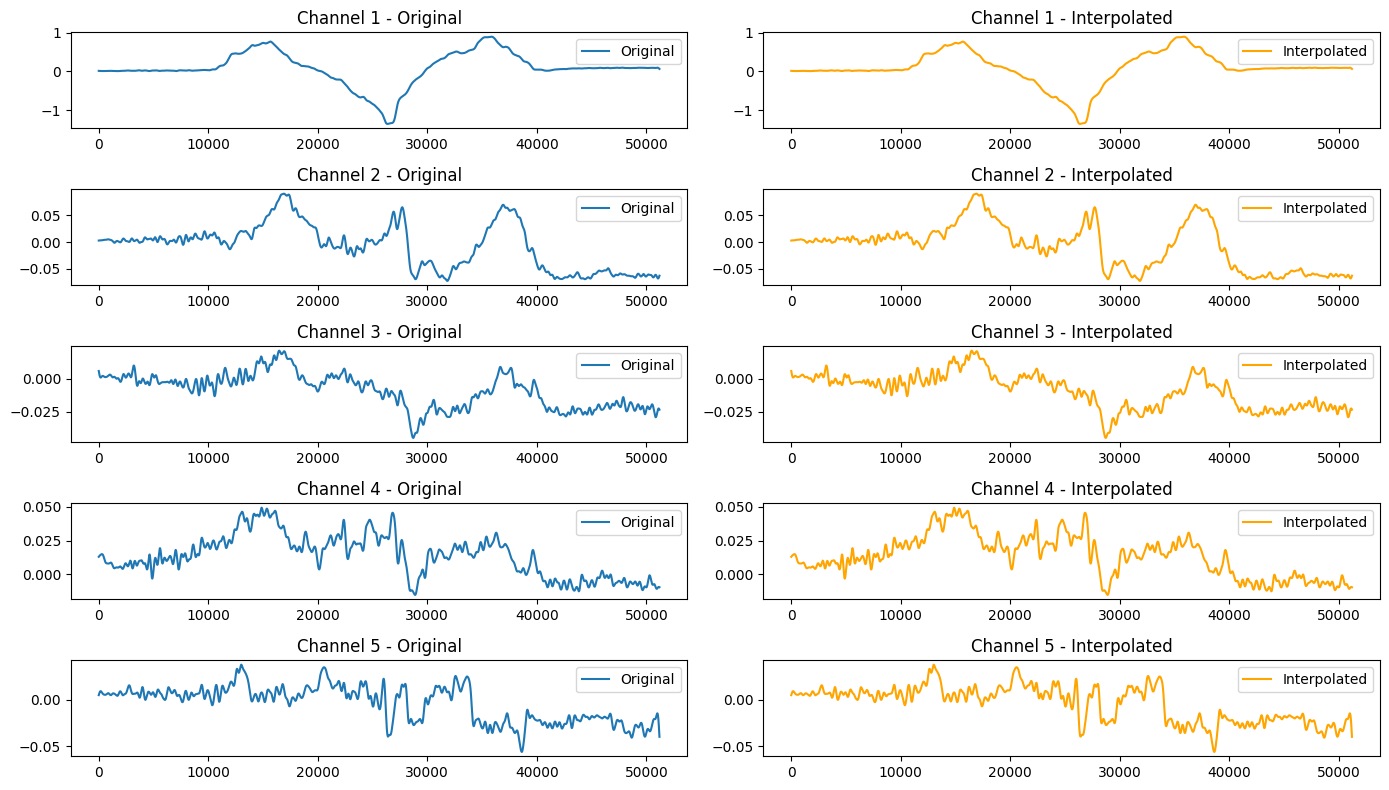

In [17]:
plot_signals(interpolated_force/0.3, interpolated_force/0.3, signal_names=["Force Channel 1", "Force Channel 2", "Force Channel 3", "Force Channel 4", "Force Channel 5"])

In [18]:
emg_signal = tf.random.normal(shape=(1000, 256))  # Example EMG signal with 1000 samples and 256 channels
force_signal = tf.random.normal(shape=(1000, 5))  # Example force signal with 1000 samples and 5 channels

data = synced_windows(emg_signal, force_signal)
print(data.element_spec)

(TensorSpec(shape=(None, 256), dtype=tf.float32, name=None), TensorSpec(shape=(None, 5), dtype=tf.float32, name=None))


In [23]:
emg_files = [([b'1dof_preprocess_finger1_sample1.hea',
                   b'1dof_preprocess_finger1_sample2.hea',
                   b'1dof_preprocess_finger1_sample3.hea'],)]
force_files = [([b'1dof_force_finger1_sample1.hea',
                     b'1dof_force_finger1_sample2.hea',
                     b'1dof_force_finger1_sample3.hea'],)]

emg_strings = [str(x, 'utf-8') for x in emg_files]
force_strings = [str(x, 'utf-8') for x in force_files]

print(emg_strings)
print(force_strings)

TypeError: decoding to str: need a bytes-like object, tuple found

In [ ]:
emg_strings

In [ ]:
force_strings